In [ ]:
# Colab setup: mount Google Drive and keep the repository/results persistent.
from pathlib import Path
from getpass import getpass
import os
import subprocess

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from comparing_dynamics.config import Config
import gc

DATA_ROOT = Path("G:/My Drive/STUDIA/PhD/Glassy_Dynamics/")

## Temperature vs. Properties plots

Langevin Dynamics.
* Not run long enough

In [15]:
metrics_to_load_from_Result = ["final_loss", "final_gradient_norm", "overlap_q", "initial_to_inherent_overlap"]
metrics = metrics_to_load_from_Result + ["temp"]
data = {metric: {} for metric in metrics}
run_names = []
# load the runs.
for temp in ['1', '0.1', '0.01', '0']:
    for seed in ['11', '19']:
        run_name = f"mnist-langevin-T-{temp}-{seed}"
        load_path = DATA_ROOT / f"inherent-structures-langevin/Result_{run_name}.pt"
        result = torch.load(load_path, weights_only=False, map_location="cpu")
        print(result.keys())
        run_names.append(run_name)

        for metric in metrics_to_load_from_Result:
            data[metric][run_name] = result[metric]
        data["temp"][run_name] = temp

dict_keys(['temperature', 'equilibration_steps', 'quench_steps_requested', 'final_loss', 'final_gradient_norm', 'overlap_q', 'initial_to_inherent_overlap', 'initial_parameters', 'equilibrated_parameters', 'inherent_parameters', 'equilibrated_model_state_dict', 'model_state_dict'])
dict_keys(['temperature', 'equilibration_steps', 'quench_steps_requested', 'final_loss', 'final_gradient_norm', 'overlap_q', 'initial_to_inherent_overlap', 'initial_parameters', 'equilibrated_parameters', 'inherent_parameters', 'equilibrated_model_state_dict', 'model_state_dict'])
dict_keys(['temperature', 'equilibration_steps', 'quench_steps_requested', 'final_loss', 'final_gradient_norm', 'overlap_q', 'initial_to_inherent_overlap', 'initial_parameters', 'equilibrated_parameters', 'inherent_parameters', 'equilibrated_model_state_dict', 'model_state_dict'])
dict_keys(['temperature', 'equilibration_steps', 'quench_steps_requested', 'final_loss', 'final_gradient_norm', 'overlap_q', 'initial_to_inherent_overlap'

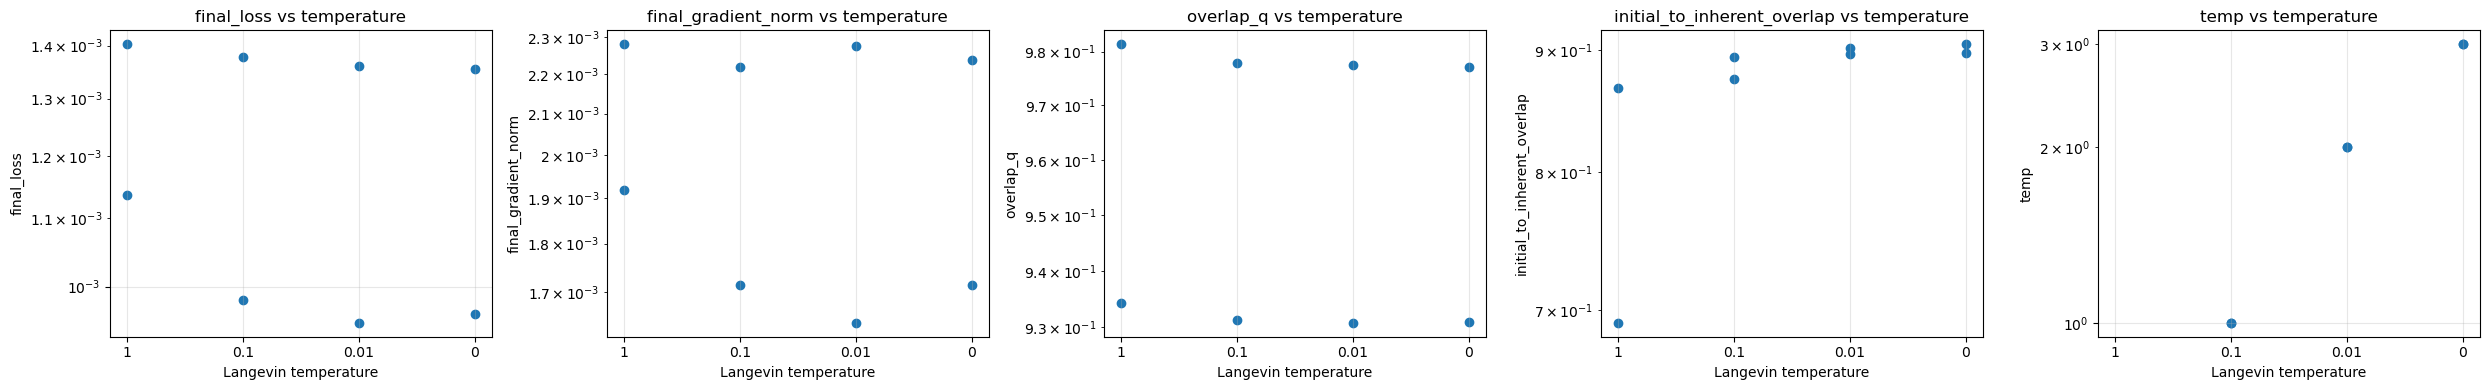

In [20]:
import matplotlib.pyplot as plt
plt.rcParams["text.usetex"] = False

plot_runs = run_names

fig, axes = plt.subplots(1, len(metrics), figsize=(5 * len(metrics), 4), squeeze=False)
for ax, (metric_name, metric_dict) in zip(axes[0], data.items()):
    runs = list(metric_dict)
    ax.scatter([data["temp"][run] for run in runs], list(metric_dict.values()))
    ax.set_xlabel("Langevin temperature")
    ax.set_ylabel(metric_name)
    ax.set_title(f"{metric_name} vs temperature")
    ax.grid(alpha=0.3)
    ax.set_yscale("log")

plt.tight_layout()
plt.show()

## SGD dynamics - from old runs

In [28]:
old_data_path = Path("G:/My Drive/STUDIA/PhD/ICML_2026_Hessian_Eigenvectors")
new_data_path = Path("G:/My Drive/STUDIA/PhD/Comparing_Dynamics/inherent-structures/")

Load metadata about the runs

In [ ]:
# Load the W&B export from the repository data directory.
metrics_path = Path("../data/wandb_export_ICML_runs.csv")
df = pd.read_csv(metrics_path)

# Normalize the W&B export so run metadata and metrics use stable column names.
df = df.rename(columns={
    "Name": "run_name",
})
required_columns = {"run_name", "opt_name", "task_name", "loss", "accuracy", "grad_norm"}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise KeyError(f"Missing columns in W&B export: {sorted(missing_columns)}")

filtered = df[
    df["opt_name"].astype(str).str.lower().eq("sgd")
    & df["task_name"].astype(str).str.lower().eq("mnist")
].drop_duplicates(subset=["run_name"])
metrics_by_run = df.set_index("run_name")
df_metrics = df  # Compatibility with the exploratory cells below.
# filtered[["run_name", "opt_name", "task_name"]]

run_names = filtered["run_name"].values
"there are " + str(len(filtered)) + " available runs"

'there are 72 available runs'

Infer the temperature

In [32]:
T = {}
for run_name in filtered["run_name"]:
    try:
        run_cfg = Config.load_from_file(run_name, str(old_data_path) + "/")
    except FileNotFoundError:
        print(f"Missing config or checkpoint: {run_name}")
        continue
    
    batch_size = run_cfg.task_params.get("batch_size")
    if batch_size is None or batch_size == 0:
        raise ValueError(f"Invalid batch size for {run_name}: {batch_size}")
    T[run_name] = run_cfg.opt_params["lr"] / batch_size

T

Missing config or checkpoint: earnest-firefly-325
Missing config or checkpoint: dry-bird-321
Missing config or checkpoint: glamorous-frost-189
Missing config or checkpoint: resilient-yogurt-188
Missing config or checkpoint: avid-glitter-96
Missing config or checkpoint: wise-voice-85
Missing config or checkpoint: jumping-wind-84
Missing config or checkpoint: daily-cosmos-66
Missing config or checkpoint: sweet-water-65
Missing config or checkpoint: celestial-fire-59
Missing config or checkpoint: restful-smoke-58
Missing config or checkpoint: drawn-sound-57
Missing config or checkpoint: fiery-forest-56
Missing config or checkpoint: eternal-silence-55
Missing config or checkpoint: silver-elevator-54
Missing config or checkpoint: graceful-brook-53
Missing config or checkpoint: curious-sun-52
Missing config or checkpoint: wild-fire-51
Missing config or checkpoint: dashing-snowflake-50
Missing config or checkpoint: still-glitter-49
Missing config or checkpoint: amber-rain-48
Missing config or

{'graceful-snowball-348': 7.8125e-05,
 'pleasant-wave-346': 7.8125e-05,
 'visionary-morning-344': 7.8125e-05,
 'worldly-dew-342': 7.8125e-05,
 'peach-wave-340': 7.8125e-05,
 'efficient-eon-339': 7.8125e-05,
 'proud-serenity-331': 7.8125e-05,
 'fine-lake-229': 7.8125e-07,
 'fanciful-night-227': 7.8125e-06,
 'eager-snow-226': 2.34375e-05,
 'jumping-aardvark-224': 1.6666666666666668e-07,
 'balmy-plant-223': 0.000234375,
 'still-haze-222': 9.765625e-06,
 'swept-totem-220': 0.00078125,
 'grateful-galaxy-219': 7.8125e-05,
 'colorful-pyramid-216': 7.8125e-07,
 'cool-valley-215': 0.00015625,
 'magic-snowflake-213': 7.8125e-06,
 'worthy-dawn-212': 0.0003125,
 'worldly-dust-210': 2.34375e-05,
 'stilted-paper-209': 1.6666666666666668e-07,
 'astral-dragon-208': 9.765625e-06,
 'fresh-bush-207': 0.000234375,
 'amber-eon-205': 7.8125e-05,
 'elated-aardvark-204': 0.00078125,
 'pleasant-cloud-203': 0.00015625,
 'efficient-jazz-202': 7.8125e-07,
 'icy-tree-201': 7.8125e-06,
 'ancient-leaf-200': 0.000312

In [ ]:
# Optional: load leading Hessian eigenvalues when those files are available.
leading_eigenvalue = {}
for run_name in filtered["run_name"]:
    result_path = EXPERIMENT_ROOT / f"hResults_{run_name}.pt"
    if not result_path.exists():
        continue
    hessian_result = torch.load(result_path, weights_only=False, map_location="cpu")
    leading_eigenvalue[run_name] = hessian_result["eig"][-1][0]
    del hessian_result
    gc.collect()

if leading_eigenvalue:
    print(
        np.max(list(leading_eigenvalue.values())),
        np.min(list(leading_eigenvalue.values())),
    )
else:
    print("No Hessian files found; using the configured quench learning rate.")

In [33]:
run_names = list(T.keys())
metrics = ["final_loss", "final_gradient_norm", "overlap_q", "initial_to_inherent_overlap"]
data = {metric: {} for metric in metrics}

for run_name in run_names:
    path_to_data = f'{new_data_path}/sgd-to-quench/Result_{run_name}.pt'
    result = torch.load(load_path, weights_only=False, map_location="cpu")
    print(result.keys())

    for metric in metrics_to_load_from_Result:
        data[metric][run_name] = result[metric]
    

dict_keys(['temperature', 'equilibration_steps', 'quench_steps_requested', 'final_loss', 'final_gradient_norm', 'overlap_q', 'initial_to_inherent_overlap', 'initial_parameters', 'equilibrated_parameters', 'inherent_parameters', 'equilibrated_model_state_dict', 'model_state_dict'])
dict_keys(['temperature', 'equilibration_steps', 'quench_steps_requested', 'final_loss', 'final_gradient_norm', 'overlap_q', 'initial_to_inherent_overlap', 'initial_parameters', 'equilibrated_parameters', 'inherent_parameters', 'equilibrated_model_state_dict', 'model_state_dict'])
dict_keys(['temperature', 'equilibration_steps', 'quench_steps_requested', 'final_loss', 'final_gradient_norm', 'overlap_q', 'initial_to_inherent_overlap', 'initial_parameters', 'equilibrated_parameters', 'inherent_parameters', 'equilibrated_model_state_dict', 'model_state_dict'])
dict_keys(['temperature', 'equilibration_steps', 'quench_steps_requested', 'final_loss', 'final_gradient_norm', 'overlap_q', 'initial_to_inherent_overlap'

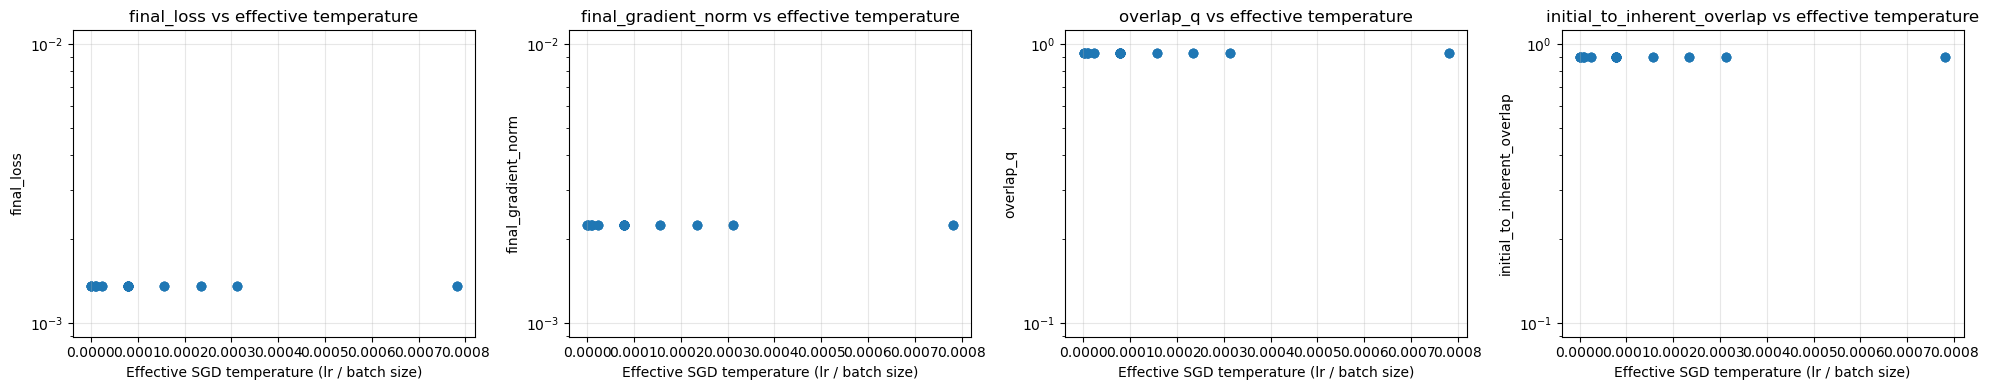

In [36]:
import matplotlib.pyplot as plt
plt.rcParams["text.usetex"] = False

plot_runs = run_names

fig, axes = plt.subplots(1, len(metrics), figsize=(5 * len(metrics), 4), squeeze=False)
for ax, (metric_name, metric_dict) in zip(axes[0], data.items()):
    runs = list(metric_dict)
    ax.scatter([T[run] for run in runs], list(metric_dict.values()))
    ax.set_xlabel("Effective SGD temperature (lr / batch size)")
    ax.set_ylabel(metric_name)
    ax.set_title(f"{metric_name} vs effective temperature")
    ax.grid(alpha=0.3)
    ax.set_yscale("log")

plt.tight_layout()
plt.show()